# Random Forest and XGBoost Comparison Using SHAP for Osteoporosis Risk Classification

## 1. Pengambilan Dataset

In [ ]:
!pip install kagglehub -q
import kagglehub

In [ ]:
path = kagglehub.dataset_download("amitvkulkarni/lifestyle-factors-influencing-osteoporosis")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lifestyle-factors-influencing-osteoporosis' dataset.
Path to dataset files: /kaggle/input/lifestyle-factors-influencing-osteoporosis


In [ ]:
import os
print(os.listdir(path))

['osteoporosis.csv']


## 2. Memuat Data ke DataFrame

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
# Sesuaikan nama file csv-nya berdasarkan hasil Cell 3
df = pd.read_csv(f"{path}/osteoporosis.csv")
print(df.shape)
df.head()

(1958, 16)


,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1


## 3. Eksplorasi Data Awal (EDA)

In [ ]:
df.info()
print()
print("Missing value per kolom:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1958 entries, 0 to 1957
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Id                   1958 non-null   int64 
 1   Age                  1958 non-null   int64 
 2   Gender               1958 non-null   object
 3   Hormonal Changes     1958 non-null   object
 4   Family History       1958 non-null   object
 5   Race/Ethnicity       1958 non-null   object
 6   Body Weight          1958 non-null   object
 7   Calcium Intake       1958 non-null   object
 8   Vitamin D Intake     1958 non-null   object
 9   Physical Activity    1958 non-null   object
 10  Smoking              1958 non-null   object
 11  Alcohol Consumption  970 non-null    object
 12  Medical Conditions   1311 non-null   object
 13  Medications          973 non-null    object
 14  Prior Fractures      1958 non-null   object
 15  Osteoporosis         1958 non-null   int64 
dtypes: int

**Distribusi kelas target (Osteoporosis):**

In [ ]:
print(df['Osteoporosis'].value_counts())

Osteoporosis
1    979
0    979
Name: count, dtype: int64


## 4. Data Cleaning

Nilai kosong (NaN) pada kolom berikut kemungkinan besar bermakna "tidak ada/tidak mengonsumsi", bukan data yang hilang secara acak, sehingga diisi dengan label `'None'`, bukan dihapus.

In [ ]:
# NaN di kolom ini kemungkinan besar bermakna "tidak ada/tidak mengonsumsi", bukan data hilang acak
cols_to_fill = ['Alcohol Consumption', 'Medical Conditions', 'Medications']

for col in cols_to_fill:
    df[col] = df[col].fillna('None')

print(df[cols_to_fill].isna().sum())

Alcohol Consumption    0
Medical Conditions     0
Medications            0
dtype: int64


Kolom `Id` dihapus karena hanya identifier, tidak relevan sebagai fitur prediktor.

In [ ]:
df = df.drop(columns=['Id'])
print(df.columns.tolist())

['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis']


In [ ]:
# Cek duplikat SETELAH Id dibuang (Id unik, jadi harus dicek tanpa Id)
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 4


“4 baris identik pada seluruh atribut dipertahankan karena memiliki Id berbeda.”

## 5. Encoding Fitur Kategorikal

Mengecek kategori unik pada tiap kolom bertipe object sebelum menentukan strategi encoding.

In [ ]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()

for col in categorical_cols:
    print(f"{col}: {df[col].unique()}")

Gender: ['Female' 'Male']
Hormonal Changes: ['Normal' 'Postmenopausal']
Family History: ['Yes' 'No']
Race/Ethnicity: ['Asian' 'Caucasian' 'African American']
Body Weight: ['Underweight' 'Normal']
Calcium Intake: ['Low' 'Adequate']
Vitamin D Intake: ['Sufficient' 'Insufficient']
Physical Activity: ['Sedentary' 'Active']
Smoking: ['Yes' 'No']
Alcohol Consumption: ['Moderate' 'None']
Medical Conditions: ['Rheumatoid Arthritis' 'None' 'Hyperthyroidism']
Medications: ['Corticosteroids' 'None']
Prior Fractures: ['Yes' 'No']


Kolom dikelompokkan menjadi fitur biner (di-*label encode*) dan fitur multi-kategori (di-*one-hot encode*).

In [ ]:
binary_cols = ['Gender', 'Hormonal Changes', 'Family History', 'Body Weight',
               'Calcium Intake', 'Vitamin D Intake', 'Physical Activity',
               'Smoking', 'Alcohol Consumption', 'Medications', 'Prior Fractures']

multi_cols = ['Race/Ethnicity', 'Medical Conditions']

**Label Encoding** untuk fitur biner:

In [ ]:
from sklearn.preprocessing import LabelEncoder

df_encoded = df.copy()
label_encoders = {}

for col in binary_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col])
    label_encoders[col] = le

df_encoded.head()

,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,69,0,0,1,Asian,1,1,1,1,1,0,Rheumatoid Arthritis,0,1,1
1,32,0,0,1,Asian,1,1,1,1,0,1,None,1,1,1
2,89,0,1,0,Caucasian,0,0,1,0,0,0,Hyperthyroidism,0,0,1
3,78,0,0,0,Caucasian,1,0,0,1,1,1,Rheumatoid Arthritis,0,0,1
4,38,1,1,1,African American,0,1,1,0,1,1,Rheumatoid Arthritis,1,1,1


**Keterangan Mapping Encoding (0/1)**

Berikut makna asli dari tiap angka hasil Label Encoding, diambil langsung dari `label_encoders` yang tersimpan.

In [ ]:
# Loop untuk setiap kolom biner yang sudah di-encode sebelumnya
for col in binary_cols:
    # label_encoders[col] menyimpan objek LabelEncoder yang sudah di-fit untuk kolom ini
    # .classes_ berisi label ASLI (teks) sebelum diubah jadi angka, misal ['Female', 'Male']
    # .transform(...) mengubah label asli itu menjadi angka hasil encoding (0, 1, dst)
    # zip(...) memasangkan tiap label asli dengan angka hasil encoding-nya
    # dict(...) mengubah pasangan tersebut jadi dictionary, contoh: {'Female': 0, 'Male': 1}
    mapping = dict(zip(label_encoders[col].classes_, label_encoders[col].transform(label_encoders[col].classes_)))

    # Cetak nama kolom beserta mapping-nya, supaya kita tahu persis
    # angka 0 dan 1 pada kolom tersebut mewakili kategori apa
    print(f"{col}: {mapping}")

Gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Hormonal Changes: {'Normal': np.int64(0), 'Postmenopausal': np.int64(1)}
Family History: {'No': np.int64(0), 'Yes': np.int64(1)}
Body Weight: {'Normal': np.int64(0), 'Underweight': np.int64(1)}
Calcium Intake: {'Adequate': np.int64(0), 'Low': np.int64(1)}
Vitamin D Intake: {'Insufficient': np.int64(0), 'Sufficient': np.int64(1)}
Physical Activity: {'Active': np.int64(0), 'Sedentary': np.int64(1)}
Smoking: {'No': np.int64(0), 'Yes': np.int64(1)}
Alcohol Consumption: {'Moderate': np.int64(0), 'None': np.int64(1)}
Medications: {'Corticosteroids': np.int64(0), 'None': np.int64(1)}
Prior Fractures: {'No': np.int64(0), 'Yes': np.int64(1)}


**One-Hot Encoding** untuk fitur multi-kategori:

In [ ]:
df_encoded = pd.get_dummies(df_encoded, columns=multi_cols, drop_first=False)

print(df_encoded.shape)
df_encoded.head()

(1958, 19)


,Age,Gender,Hormonal Changes,Family History,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medications,Prior Fractures,Osteoporosis,Race/Ethnicity_African American,Race/Ethnicity_Asian,Race/Ethnicity_Caucasian,Medical Conditions_Hyperthyroidism,Medical Conditions_None,Medical Conditions_Rheumatoid Arthritis
0,69,0,0,1,1,1,1,1,1,0,0,1,1,False,True,False,False,False,True
1,32,0,0,1,1,1,1,1,0,1,1,1,1,False,True,False,False,True,False
2,89,0,1,0,0,0,1,0,0,0,0,0,1,False,False,True,True,False,False
3,78,0,0,0,1,0,0,1,1,1,0,0,1,False,False,True,False,False,True
4,38,1,1,1,0,1,1,0,1,1,1,1,1,True,False,False,False,False,True


In [ ]:
print(df_encoded.columns.tolist())
print()
print(df_encoded.dtypes)

['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake', 'Physical Activity', 'Smoking', 'Alcohol Consumption', 'Medications', 'Prior Fractures', 'Osteoporosis', 'Race/Ethnicity_African American', 'Race/Ethnicity_Asian', 'Race/Ethnicity_Caucasian', 'Medical Conditions_Hyperthyroidism', 'Medical Conditions_None', 'Medical Conditions_Rheumatoid Arthritis']

Age                                        int64
Gender                                     int64
Hormonal Changes                           int64
Family History                             int64
Body Weight                                int64
Calcium Intake                             int64
Vitamin D Intake                           int64
Physical Activity                          int64
Smoking                                    int64
Alcohol Consumption                        int64
Medications                                int64
Prior Fractures                            int64
Os

## 6. Pemisahan Fitur, Target, dan Train-Test Split

In [ ]:
X = df_encoded.drop(columns=['Osteoporosis'])
y = df_encoded['Osteoporosis']

print(X.shape, y.shape)

(1958, 18) (1958,)


Split data 80:20 dengan `stratify=y` untuk menjaga proporsi kelas tetap seimbang pada data latih maupun data uji.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Distribusi train:", y_train.value_counts().to_dict())
print("Distribusi test:", y_test.value_counts().to_dict())

Train: (1566, 18) | Test: (392, 18)
Distribusi train: {0: 783, 1: 783}
Distribusi test: {1: 196, 0: 196}


## 7. Pemodelan: Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Performance:")
print(classification_report(y_test, y_pred_rf))

Random Forest Performance:
              precision    recall  f1-score   support

           0       0.76      0.95      0.85       196
           1       0.93      0.70      0.80       196

    accuracy                           0.83       392
   macro avg       0.85      0.83      0.82       392
weighted avg       0.85      0.83      0.82       392



## 8. Pemodelan: XGBoost

In [ ]:
!pip install xgboost -q
from xgboost import XGBClassifier

xgb_model = XGBClassifier(n_estimators=100, max_depth=6, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Performance:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Performance:
              precision    recall  f1-score   support

           0       0.81      0.93      0.87       196
           1       0.92      0.79      0.85       196

    accuracy                           0.86       392
   macro avg       0.87      0.86      0.86       392
weighted avg       0.87      0.86      0.86       392



## 9. Validasi Silang (5-Fold Cross-Validation)

Dilakukan sebagai estimasi performa tambahan pada seluruh data; tidak dipakai untuk memilih hyperparameter.

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores_rf = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')
cv_scores_xgb = cross_val_score(xgb_model, X, y, cv=5, scoring='accuracy')

print("Random Forest CV Accuracy:", cv_scores_rf)
print("Rata-rata:", cv_scores_rf.mean(), "| Std:", cv_scores_rf.std())
print()
print("XGBoost CV Accuracy:", cv_scores_xgb)
print("Rata-rata:", cv_scores_xgb.mean(), "| Std:", cv_scores_xgb.std())

Random Forest CV Accuracy: [0.83163265 0.87244898 0.85969388 0.84143223 0.87468031]
Rata-rata: 0.8559776084346783 | Std: 0.01696556915381763

XGBoost CV Accuracy: [0.83928571 0.90306122 0.91071429 0.85421995 0.88235294]
Rata-rata: 0.8779268229030741 | Std: 0.0275009001171912


## 10. Confusion Matrix

A. Baseline

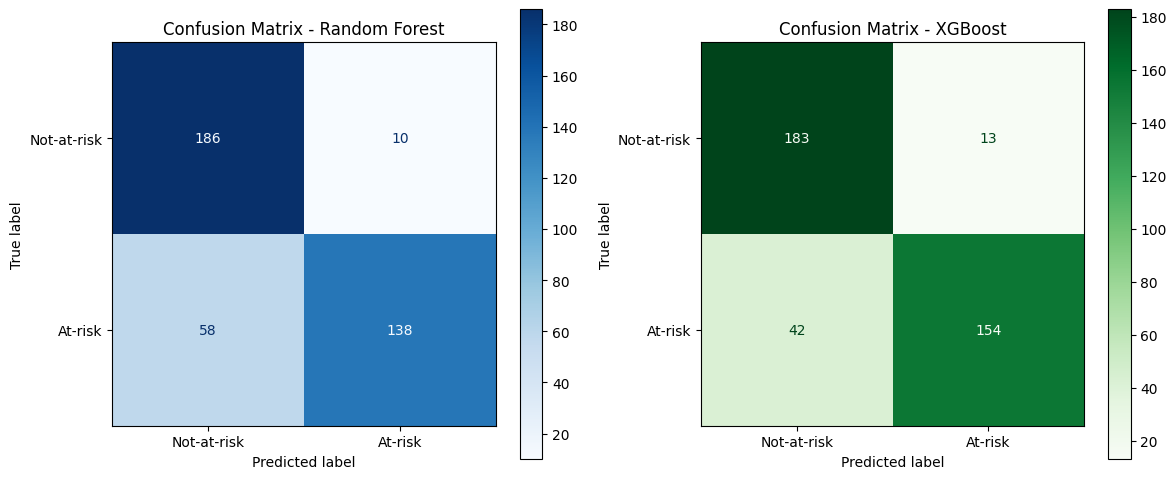

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ['Not-at-risk', 'At-risk']
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_rf = confusion_matrix(y_test, y_pred_rf)
ConfusionMatrixDisplay(cm_rf, display_labels=labels).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Confusion Matrix - Random Forest')

cm_xgb = confusion_matrix(y_test, y_pred_xgb)
ConfusionMatrixDisplay(cm_xgb, display_labels=labels).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Confusion Matrix - XGBoost')

plt.tight_layout()
plt.savefig('figure_1_confusion_matrix.png', dpi=350, bbox_inches='tight')
plt.show()

B. Tuned

In [ ]:
confusion_matrix(y_test, y_pred_xgb_tuned)

array([[195,   1],
       [ 45, 151]])

In [ ]:
confusion_matrix(y_test, y_pred_rf_tuned)

array([[193,   3],
       [ 61, 135]])

## 11. Optimasi Model: Hyperparameter Tuning (GridSearchCV)

Tahap ini mencari kombinasi parameter terbaik untuk Random Forest dan XGBoost menggunakan pencarian grid (*GridSearchCV*) dengan validasi silang 5-fold, untuk melihat apakah performa model baseline pada Bagian 7 dan 8 masih bisa ditingkatkan.

In [ ]:
# Import tool untuk pencarian kombinasi hyperparameter terbaik secara otomatis
from sklearn.model_selection import GridSearchCV

# Definisikan kombinasi parameter yang ingin diuji untuk Random Forest
param_grid_rf = {
    'n_estimators': [100, 200, 300],      # jumlah pohon dalam forest
    'max_depth': [5, 10, 15, None],       # kedalaman maksimum tiap pohon
    'min_samples_split': [2, 5, 10]       # minimal sampel untuk melakukan split
}

# GridSearchCV akan mencoba SEMUA kombinasi di atas, masing-masing divalidasi dengan 5-fold CV
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),  # model dasar yang akan dituning
    param_grid_rf,        # grid kombinasi parameter yang akan dicoba
    cv=5,                 # jumlah fold cross-validation
    scoring='accuracy',   # metrik yang dipakai untuk menilai kombinasi terbaik
    n_jobs=-1              # gunakan semua core CPU yang tersedia agar lebih cepat
)

# Latih GridSearchCV pada data training -> ini otomatis mencoba semua kombinasi parameter
grid_rf.fit(X_train, y_train)

# Tampilkan kombinasi parameter yang menghasilkan skor CV terbaik
print("Best params RF:", grid_rf.best_params_)
print("Best CV score RF:", grid_rf.best_score_)

# Ambil model Random Forest terbaik hasil tuning (sudah otomatis di-fit ulang oleh GridSearchCV)
rf_model_tuned = grid_rf.best_estimator_

# Uji model terbaik ini pada data test yang belum pernah dilihat model
y_pred_rf_tuned = rf_model_tuned.predict(X_test)

print("\nRandom Forest (Tuned) Performance:")
print(classification_report(y_test, y_pred_rf_tuned))

Best params RF: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
Best CV score RF: 0.8627073116135204

Random Forest (Tuned) Performance:
              precision    recall  f1-score   support

           0       0.76      0.98      0.86       196
           1       0.98      0.69      0.81       196

    accuracy                           0.84       392
   macro avg       0.87      0.84      0.83       392
weighted avg       0.87      0.84      0.83       392



In [ ]:
# Definisikan kombinasi parameter yang ingin diuji untuk XGBoost
param_grid_xgb = {
    'n_estimators': [100, 200, 300],    # jumlah pohon/estimator boosting
    'max_depth': [3, 6, 9],             # kedalaman maksimum tiap pohon
    'learning_rate': [0.01, 0.1, 0.2]   # seberapa besar kontribusi tiap pohon baru
}

# Sama seperti Random Forest, coba semua kombinasi dengan validasi silang 5-fold
grid_xgb = GridSearchCV(
    XGBClassifier(random_state=42, eval_metric='logloss'),  # model dasar yang akan dituning
    param_grid_xgb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Latih GridSearchCV -> mencoba seluruh kombinasi parameter pada data training
grid_xgb.fit(X_train, y_train)

# Tampilkan kombinasi parameter terbaik beserta skor CV-nya
print("Best params XGBoost:", grid_xgb.best_params_)
print("Best CV score XGBoost:", grid_xgb.best_score_)

# Ambil model XGBoost terbaik hasil tuning
xgb_model_tuned = grid_xgb.best_estimator_

# Uji model terbaik ini pada data test
y_pred_xgb_tuned = xgb_model_tuned.predict(X_test)

print("\nXGBoost (Tuned) Performance:")
print(classification_report(y_test, y_pred_xgb_tuned))

Best params XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Best CV score XGBoost: 0.9157119309741356

XGBoost (Tuned) Performance:
              precision    recall  f1-score   support

           0       0.81      0.99      0.89       196
           1       0.99      0.77      0.87       196

    accuracy                           0.88       392
   macro avg       0.90      0.88      0.88       392
weighted avg       0.90      0.88      0.88       392



## 11.1 Perbandingan Baseline vs Tuned pada Skema yang Sebanding

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, recall_score

# Baseline CV pada DATA TRAINING saja (folds sama dengan GridSearchCV: StratifiedKFold 5, tanpa shuffle)
cv_tr_rf = cross_val_score(clone(rf_model), X_train, y_train, cv=5, scoring='accuracy')
cv_tr_xgb = cross_val_score(clone(xgb_model), X_train, y_train, cv=5, scoring='accuracy')

tabel = pd.DataFrame([
    {'Model': 'Random Forest',
     'Baseline CV (train)': cv_tr_rf.mean(),
     'Tuned CV (train)': grid_rf.best_score_,
     'Baseline Test Acc': accuracy_score(y_test, y_pred_rf),
     'Tuned Test Acc': accuracy_score(y_test, y_pred_rf_tuned),
     'Baseline Test Recall': recall_score(y_test, y_pred_rf),
     'Tuned Test Recall': recall_score(y_test, y_pred_rf_tuned)},
    {'Model': 'XGBoost',
     'Baseline CV (train)': cv_tr_xgb.mean(),
     'Tuned CV (train)': grid_xgb.best_score_,
     'Baseline Test Acc': accuracy_score(y_test, y_pred_xgb),
     'Tuned Test Acc': accuracy_score(y_test, y_pred_xgb_tuned),
     'Baseline Test Recall': recall_score(y_test, y_pred_xgb),
     'Tuned Test Recall': recall_score(y_test, y_pred_xgb_tuned)},
]).round(4)

print(tabel.to_string(index=False))

        Model  Baseline CV (train)  Tuned CV (train)  Baseline Test Acc  Tuned Test Acc  Baseline Test Recall  Tuned Test Recall
Random Forest               0.8557            0.8627             0.8265          0.8367                0.7041             0.6888
      XGBoost               0.8908            0.9157             0.8597          0.8827                0.7857             0.7704


## 12. Uji Stabilitas Model dengan Beberapa Random State

Untuk memastikan performa tidak bergantung pada satu pembagian data, GridSearchCV diulang di setiap split (5 *random state*): hyperparameter dicari hanya pada data latih split tersebut, lalu dievaluasi pada data uji split yang sama. Hasil dengan parameter tetap dari split 42 disimpan sebagai pembanding.

In [ ]:
# Uji stabilitas dengan TUNING ULANG di setiap split (nested):
# hyperparameter dicari hanya pada data latih tiap split, jadi data uji tidak ikut memilih parameter.
random_states = [0, 21, 42, 84, 100]

hasil_robustness = []   # hasil utama (tuning ulang per split)
hasil_fixed = []        # pembanding: parameter tetap dari split 42 (cara lama)
log_params = []

for rs in random_states:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs, stratify=y)

    # Random Forest: GridSearchCV hanya pada data latih split ini
    gs_rf = GridSearchCV(RandomForestClassifier(random_state=rs, n_jobs=-1),
                         param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)
    gs_rf.fit(X_tr, y_tr)
    acc_rf = accuracy_score(y_te, gs_rf.best_estimator_.predict(X_te))

    # XGBoost: GridSearchCV hanya pada data latih split ini
    gs_xgb = GridSearchCV(XGBClassifier(random_state=rs, eval_metric='logloss'),
                          param_grid_xgb, cv=5, scoring='accuracy', n_jobs=-1)
    gs_xgb.fit(X_tr, y_tr)
    acc_xgb = accuracy_score(y_te, gs_xgb.best_estimator_.predict(X_te))

    # Pembanding (cara lama): parameter tetap hasil tuning split 42
    rf_fix = RandomForestClassifier(n_estimators=100, max_depth=5, min_samples_split=5,
                                    random_state=rs, n_jobs=-1)
    rf_fix.fit(X_tr, y_tr)
    xgb_fix = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                            random_state=rs, eval_metric='logloss')
    xgb_fix.fit(X_tr, y_tr)
    acc_rf_fix = accuracy_score(y_te, rf_fix.predict(X_te))
    acc_xgb_fix = accuracy_score(y_te, xgb_fix.predict(X_te))

    hasil_robustness.append({'Random_State': rs, 'RF_Accuracy': acc_rf, 'XGB_Accuracy': acc_xgb})
    hasil_fixed.append({'Random_State': rs, 'RF_Accuracy': acc_rf_fix, 'XGB_Accuracy': acc_xgb_fix})
    log_params.append({'Random_State': rs, 'RF_best': gs_rf.best_params_, 'XGB_best': gs_xgb.best_params_})
    print(f"Random State {rs} -> RF: {acc_rf:.4f} (param tetap: {acc_rf_fix:.4f}), "
          f"XGBoost: {acc_xgb:.4f} (param tetap: {acc_xgb_fix:.4f})")

df_robustness = pd.DataFrame(hasil_robustness)
df_robustness_fixed = pd.DataFrame(hasil_fixed)
df_params = pd.DataFrame(log_params)

print("\n=== RINGKASAN (tuning ulang per split) ===")
print(df_robustness)
print(f"\nRF  -> Rata-rata: {df_robustness['RF_Accuracy'].mean():.4f}, Std: {df_robustness['RF_Accuracy'].std():.4f}")
print(f"XGB -> Rata-rata: {df_robustness['XGB_Accuracy'].mean():.4f}, Std: {df_robustness['XGB_Accuracy'].std():.4f}")

print("\n=== PEMBANDING (parameter tetap dari split 42) ===")
print(f"RF  -> Rata-rata: {df_robustness_fixed['RF_Accuracy'].mean():.4f}, Std: {df_robustness_fixed['RF_Accuracy'].std():.4f}")
print(f"XGB -> Rata-rata: {df_robustness_fixed['XGB_Accuracy'].mean():.4f}, Std: {df_robustness_fixed['XGB_Accuracy'].std():.4f}")

print("\nParameter terbaik per split:")
print(df_params.to_string(index=False))

Random State 0 -> RF: 0.8418 (param tetap: 0.8469), XGBoost: 0.9107 (param tetap: 0.9107)
Random State 21 -> RF: 0.8750 (param tetap: 0.8750), XGBoost: 0.9235 (param tetap: 0.9260)
Random State 42 -> RF: 0.8367 (param tetap: 0.8367), XGBoost: 0.8827 (param tetap: 0.8827)
Random State 84 -> RF: 0.8648 (param tetap: 0.8648), XGBoost: 0.9158 (param tetap: 0.9184)
Random State 100 -> RF: 0.8724 (param tetap: 0.8724), XGBoost: 0.9337 (param tetap: 0.9337)

=== RINGKASAN (tuning ulang per split) ===
   Random_State  RF_Accuracy  XGB_Accuracy
0             0     0.841837      0.910714
1            21     0.875000      0.923469
2            42     0.836735      0.882653
3            84     0.864796      0.915816
4           100     0.872449      0.933673

RF  -> Rata-rata: 0.8582, Std: 0.0177
XGB -> Rata-rata: 0.9133, Std: 0.0192

=== PEMBANDING (parameter tetap dari split 42) ===
RF  -> Rata-rata: 0.8592, Std: 0.0167
XGB -> Rata-rata: 0.9143, Std: 0.0196

Parameter terbaik per split:
 Random_

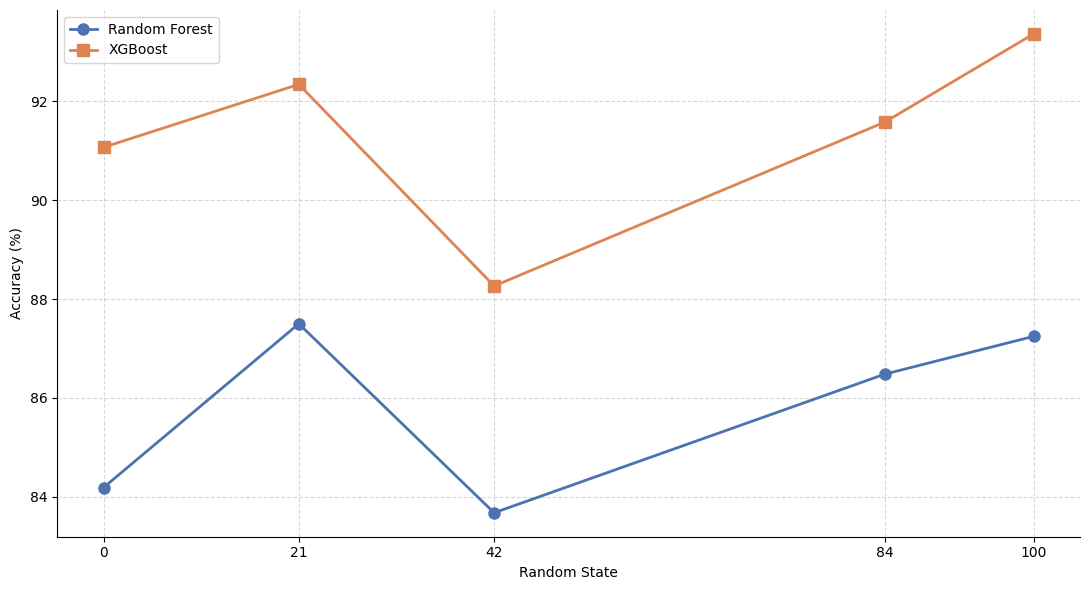

In [ ]:
# Visualisasi Akurasi Random State per Model
fig, ax = plt.subplots(figsize=(11, 6))

# Plot garis Random Forest
ax.plot(df_robustness['Random_State'], df_robustness['RF_Accuracy'] * 100,
        marker='o', markersize=8, linewidth=2, color='#4C72B0', label='Random Forest')

# Plot garis XGBoost
ax.plot(df_robustness['Random_State'], df_robustness['XGB_Accuracy'] * 100,
        marker='s', markersize=8, linewidth=2, color='#DD8452', label='XGBoost')

ax.set_xlabel('Random State')
ax.set_ylabel('Accuracy (%)')
ax.set_xticks(df_robustness['Random_State'])
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figure_3_robustness.png', dpi=350, bbox_inches='tight')
plt.show()

RF : [82.65, 83.67, np.float64(85.82)] SD: 1.77
XGB: [85.97, 88.27, np.float64(91.33)] SD: 1.92


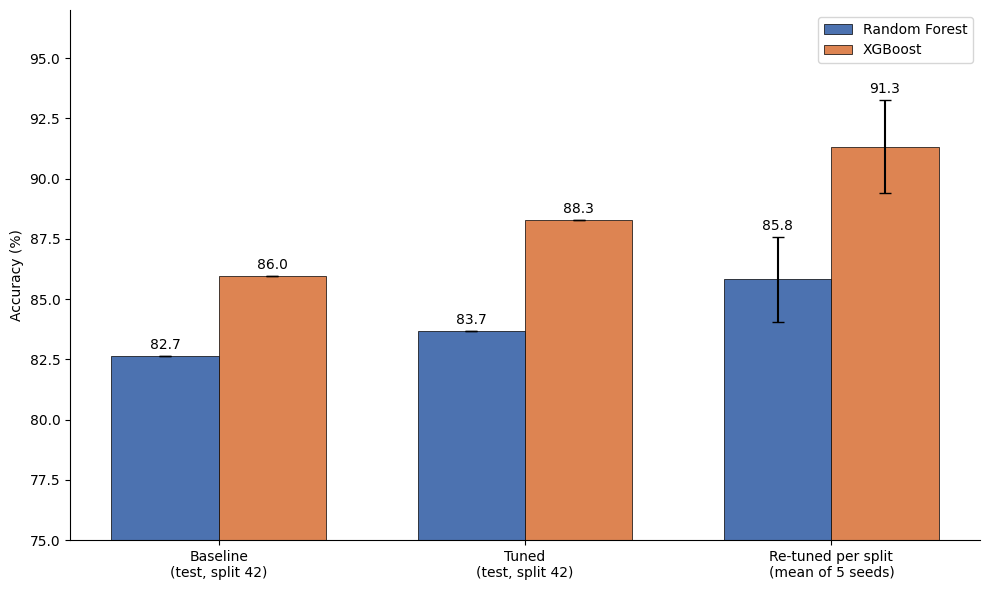

In [ ]:
# Visualisasi akurasi di semua tahap evaluasi (nilai dihitung dari variabel, bukan diketik manual)
tahap = ['Baseline\n(test, split 42)', 'Tuned\n(test, split 42)', 'Re-tuned per split\n(mean of 5 seeds)']

akurasi_rf = [accuracy_score(y_test, y_pred_rf) * 100,
              accuracy_score(y_test, y_pred_rf_tuned) * 100,
              df_robustness['RF_Accuracy'].mean() * 100]
akurasi_xgb = [accuracy_score(y_test, y_pred_xgb) * 100,
               accuracy_score(y_test, y_pred_xgb_tuned) * 100,
               df_robustness['XGB_Accuracy'].mean() * 100]

# Error bar (SD) hanya untuk skema lima seed
sd_rf = [0, 0, df_robustness['RF_Accuracy'].std() * 100]
sd_xgb = [0, 0, df_robustness['XGB_Accuracy'].std() * 100]

print("RF :", [round(v, 2) for v in akurasi_rf], "SD:", round(sd_rf[2], 2))
print("XGB:", [round(v, 2) for v in akurasi_xgb], "SD:", round(sd_xgb[2], 2))

x = np.arange(len(tahap))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 6))

bars_rf = ax.bar(x - width/2, akurasi_rf, width, yerr=sd_rf, capsize=4,
                 label='Random Forest', color='#4C72B0', edgecolor='black', linewidth=0.5)
bars_xgb = ax.bar(x + width/2, akurasi_xgb, width, yerr=sd_xgb, capsize=4,
                  label='XGBoost', color='#DD8452', edgecolor='black', linewidth=0.5)

for bars, sds in [(bars_rf, sd_rf), (bars_xgb, sd_xgb)]:
    for bar, sd in zip(bars, sds):
        h = bar.get_height()
        ax.annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width() / 2, h + sd),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Accuracy (%)')
ax.set_ylim(75, 97)
ax.set_xticks(x)
ax.set_xticklabels(tahap)
ax.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figure_2_comparison.png', dpi=350, bbox_inches='tight')
plt.show()

## 12.1 Pembanding Sederhana: Model yang Hanya Memakai Usia

Usia sangat dominan pada analisis SHAP. Untuk melihat apakah 17 fitur lain benar-benar menambah kemampuan prediksi, model yang hanya memakai fitur Age dilatih dengan split dan metrik evaluasi yang sama.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

X_train_age, X_test_age = X_train[['Age']], X_test[['Age']]

pembanding = {
    'LogReg (Age only)': LogisticRegression(max_iter=1000),
    'RF tuned (Age only)': clone(rf_model_tuned),
    'XGB tuned (Age only)': clone(xgb_model_tuned),
}

rows = []
for nama, mdl in pembanding.items():
    mdl.fit(X_train_age, y_train)
    pred = mdl.predict(X_test_age)
    rows.append({'Model': nama,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision (At-risk)': precision_score(y_test, pred),
                 'Recall (At-risk)': recall_score(y_test, pred),
                 'F1 (At-risk)': f1_score(y_test, pred)})

# Model lengkap (18 fitur) pada data uji yang sama, sebagai acuan
for nama, pred in [('RF tuned (18 fitur)', y_pred_rf_tuned), ('XGB tuned (18 fitur)', y_pred_xgb_tuned)]:
    rows.append({'Model': nama,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision (At-risk)': precision_score(y_test, pred),
                 'Recall (At-risk)': recall_score(y_test, pred),
                 'F1 (At-risk)': f1_score(y_test, pred)})

df_age_only = pd.DataFrame(rows).round(4)
print(df_age_only.to_string(index=False))

               Model  Accuracy  Precision (At-risk)  Recall (At-risk)  F1 (At-risk)
   LogReg (Age only)    0.7806               0.8056            0.7398        0.7713
 RF tuned (Age only)    0.8852               1.0000            0.7704        0.8703
XGB tuned (Age only)    0.8852               1.0000            0.7704        0.8703
 RF tuned (18 fitur)    0.8367               0.9783            0.6888        0.8084
XGB tuned (18 fitur)    0.8827               0.9934            0.7704        0.8678


In [ ]:
# Pembanding hanya-usia di lima split yang sama dengan uji stabilitas (konfigurasi sederhana, tanpa tuning)
hasil_age = []
for rs in random_states:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs, stratify=y)
    a_tr, a_te = X_tr[['Age']], X_te[['Age']]

    lr = LogisticRegression(max_iter=1000).fit(a_tr, y_tr)
    rf_a = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=rs, n_jobs=-1).fit(a_tr, y_tr)
    xgb_a = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                          random_state=rs, eval_metric='logloss').fit(a_tr, y_tr)

    hasil_age.append({'Random_State': rs,
                      'LogReg_Age': accuracy_score(y_te, lr.predict(a_te)),
                      'RF_Age': accuracy_score(y_te, rf_a.predict(a_te)),
                      'XGB_Age': accuracy_score(y_te, xgb_a.predict(a_te))})

df_age = pd.DataFrame(hasil_age)
print(df_age.round(4).to_string(index=False))
print()
for kolom in ['LogReg_Age', 'RF_Age', 'XGB_Age']:
    print(f"{kolom}: rata-rata {df_age[kolom].mean():.4f}, std {df_age[kolom].std():.4f}")
print(f"\nPembanding model lengkap -> RF {df_robustness['RF_Accuracy'].mean():.4f}, XGB {df_robustness['XGB_Accuracy'].mean():.4f}")

 Random_State  LogReg_Age  RF_Age  XGB_Age
            0      0.7934  0.8750   0.9107
           21      0.8189  0.8980   0.9260
           42      0.7806  0.8673   0.8852
           84      0.8189  0.8878   0.9184
          100      0.8469  0.8954   0.9337

LogReg_Age: rata-rata 0.8117, std 0.0257
RF_Age: rata-rata 0.8847, std 0.0132
XGB_Age: rata-rata 0.9148, std 0.0186

Pembanding model lengkap -> RF 0.8582, XGB 0.9133


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

# 1) Sebaran usia per kelas pada seluruh dataset
print("Statistik Age per kelas (0 = Not-at-risk, 1 = At-risk):")
print(df.groupby('Osteoporosis')['Age'].describe().round(2))

# 2) Proporsi at-risk per rentang usia
bins = [0, 29, 39, 49, 59, 69, 79, 120]
rentang = pd.cut(df['Age'], bins=bins)
print("\nJumlah kasus per rentang usia dan kelas:")
tabel_usia = pd.crosstab(rentang, df['Osteoporosis'])
tabel_usia['% At-risk'] = (tabel_usia[1] / tabel_usia.sum(axis=1) * 100).round(1)
print(tabel_usia)

# 3) Aturan satu ambang usia (decision stump) dilatih di training, diuji di test yang sama
stump = DecisionTreeClassifier(max_depth=1, random_state=42).fit(X_train[['Age']], y_train)
ambang = stump.tree_.threshold[0]
pred_stump = stump.predict(X_test[['Age']])
tn, fp, fn, tp = confusion_matrix(y_test, pred_stump).ravel()

print(f"\nAmbang usia yang dipelajari: Age <= {ambang:.1f} -> Not-at-risk, selainnya At-risk")
print(f"Accuracy {accuracy_score(y_test, pred_stump):.4f} | "
      f"Precision {precision_score(y_test, pred_stump):.4f} | "
      f"Recall {recall_score(y_test, pred_stump):.4f}")
print(f"TN {tn} | FP {fp} | FN {fn} | TP {tp}")

Statistik Age per kelas (0 = Not-at-risk, 1 = At-risk):
              count   mean    std   min   25%   50%   75%   max
Osteoporosis                                                   
0             979.0  24.34   6.11  18.0  19.0  22.0  29.0  38.0
1             979.0  53.86  20.96  18.0  36.0  53.0  72.0  90.0

Jumlah kasus per rentang usia dan kelas:
Osteoporosis    0    1  % At-risk
Age                              
(0, 29]       794  157       16.5
(29, 39]      185  129       41.1
(39, 49]        0  138      100.0
(49, 59]        0  140      100.0
(59, 69]        0  135      100.0
(69, 79]        0  146      100.0
(79, 120]       0  134      100.0

Ambang usia yang dipelajari: Age <= 38.5 -> Not-at-risk, selainnya At-risk
Accuracy 0.8393 | Precision 1.0000 | Recall 0.6786
TN 196 | FP 0 | FN 63 | TP 133


In [ ]:
from sklearn.base import clone

# Subgrup usia <= 38: satu-satunya rentang yang memuat kedua kelas
m_tr = X_train['Age'] <= 38
m_te = X_test['Age'] <= 38
Xtr_y, ytr_y = X_train[m_tr], y_train[m_tr]
Xte_y, yte_y = X_test[m_te], y_test[m_te]

print("Subgrup Age <= 38 -> train:", Xtr_y.shape[0], "| test:", Xte_y.shape[0])
print("Distribusi test:", yte_y.value_counts().to_dict())
print(f"Acuan (tebak semua Not-at-risk): accuracy {(yte_y == 0).mean():.4f}\n")

semua_fitur = list(X.columns)
kandidat = {
    'XGB (Age only)': (clone(xgb_model_tuned), ['Age']),
    'XGB (18 fitur)': (clone(xgb_model_tuned), semua_fitur),
    'RF (Age only)':  (clone(rf_model_tuned),  ['Age']),
    'RF (18 fitur)':  (clone(rf_model_tuned),  semua_fitur),
}

rows = []
for nama, (mdl, cols) in kandidat.items():
    mdl.fit(Xtr_y[cols], ytr_y)
    pred = mdl.predict(Xte_y[cols])
    rows.append({'Model': nama,
                 'Accuracy': accuracy_score(yte_y, pred),
                 'Precision (At-risk)': precision_score(yte_y, pred, zero_division=0),
                 'Recall (At-risk)': recall_score(yte_y, pred),
                 'F1 (At-risk)': f1_score(yte_y, pred)})

print(pd.DataFrame(rows).round(4).to_string(index=False))

Subgrup Age <= 38 -> train: 997 | test: 259
Distribusi test: {0: 196, 1: 63}
Acuan (tebak semua Not-at-risk): accuracy 0.7568

         Model  Accuracy  Precision (At-risk)  Recall (At-risk)  F1 (At-risk)
XGB (Age only)    0.8263               1.0000            0.2857        0.4444
XGB (18 fitur)    0.8147               0.8571            0.2857        0.4286
 RF (Age only)    0.8263               1.0000            0.2857        0.4444
 RF (18 fitur)    0.7568               0.0000            0.0000        0.0000


## 12.2 Evaluasi Threshold untuk Pre-Screening

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import precision_recall_curve, confusion_matrix

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
target_recall = 0.90   # target sensitivitas untuk pre-screening

rows = []
for nama, mdl in [('Random Forest', rf_model_tuned), ('XGBoost', xgb_model_tuned)]:
    # Probabilitas out-of-fold HANYA dari data training (test tidak dipakai memilih threshold)
    proba_oof = cross_val_predict(clone(mdl), X_train, y_train, cv=skf,
                                  method='predict_proba')[:, 1]

    # Threshold terbesar yang masih memenuhi target recall pada training-CV
    prec, rec, thr = precision_recall_curve(y_train, proba_oof)
    ok = np.where(rec[:-1] >= target_recall)[0]
    t_pilih = thr[ok[-1]] if len(ok) else 0.5

    # Evaluasi di test: threshold default 0.5 vs threshold terpilih
    proba_test = mdl.predict_proba(X_test)[:, 1]
    for label_thr, t in [('0.50 (default)', 0.5), (f'{t_pilih:.3f} (training-CV)', t_pilih)]:
        pred = (proba_test >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({'Model': nama, 'Threshold': label_thr,
                     'Accuracy': (tp + tn) / (tp + tn + fp + fn),
                     'Precision': tp / (tp + fp) if (tp + fp) else np.nan,
                     'Recall': tp / (tp + fn),
                     'FN': fn, 'FP': fp})

df_threshold = pd.DataFrame(rows).round(4)
print(df_threshold.to_string(index=False))

        Model           Threshold  Accuracy  Precision  Recall  FN  FP
Random Forest      0.50 (default)    0.8367     0.9783  0.6888  61   3
Random Forest 0.281 (training-CV)    0.7449     0.7000  0.8571  28  72
      XGBoost      0.50 (default)    0.8827     0.9934  0.7704  45   1
      XGBoost 0.178 (training-CV)    0.7832     0.7606  0.8265  34  51


## 13. Explainable AI dengan SHAP

Seluruh analisis SHAP dikumpulkan dalam satu bagian ini secara berurutan: instalasi & perhitungan nilai SHAP, ringkasan pengaruh fitur (summary & bar plot), studi kasus individu (waterfall plot), analisis hubungan detail fitur Age (dependence plot), hingga perbandingan feature importance antara Random Forest dan XGBoost.

In [ ]:
!pip install shap -q
import shap

In [ ]:
explainer = shap.TreeExplainer(xgb_model_tuned)
shap_values = explainer.shap_values(X_test)

print("Shape SHAP values:", shap_values.shape)

Shape SHAP values: (392, 18)


In [ ]:
# Buat explainer SHAP khusus untuk model Random Forest
explainer_rf = shap.TreeExplainer(rf_model_tuned)

# Hitung nilai SHAP untuk seluruh data test menggunakan model Random Forest
shap_values_rf = explainer_rf.shap_values(X_test)

# Ubah hasilnya menjadi numpy array agar bentuknya (shape) bisa diperiksa dengan mudah
shap_values_rf_arr = np.array(shap_values_rf)

# Untuk RandomForestClassifier, hasilnya berbentuk 3 dimensi: (jumlah_sampel, jumlah_fitur, jumlah_kelas)
# Karena kita hanya tertarik pada kelas 1 (Berisiko), ambil irisan array di kelas tersebut (index 1)
shap_values_rf_plot = shap_values_rf_arr[:, :, 1]

# Cek ulang bentuk array setelah diseleksi, harus jadi 2 dimensi: (jumlah_sampel, jumlah_fitur)
print("Shape setelah diperbaiki:", shap_values_rf_plot.shape)

Shape setelah diperbaiki: (392, 18)


### 13.1 SHAP Summary Plot (Beeswarm)

A. XGBoost

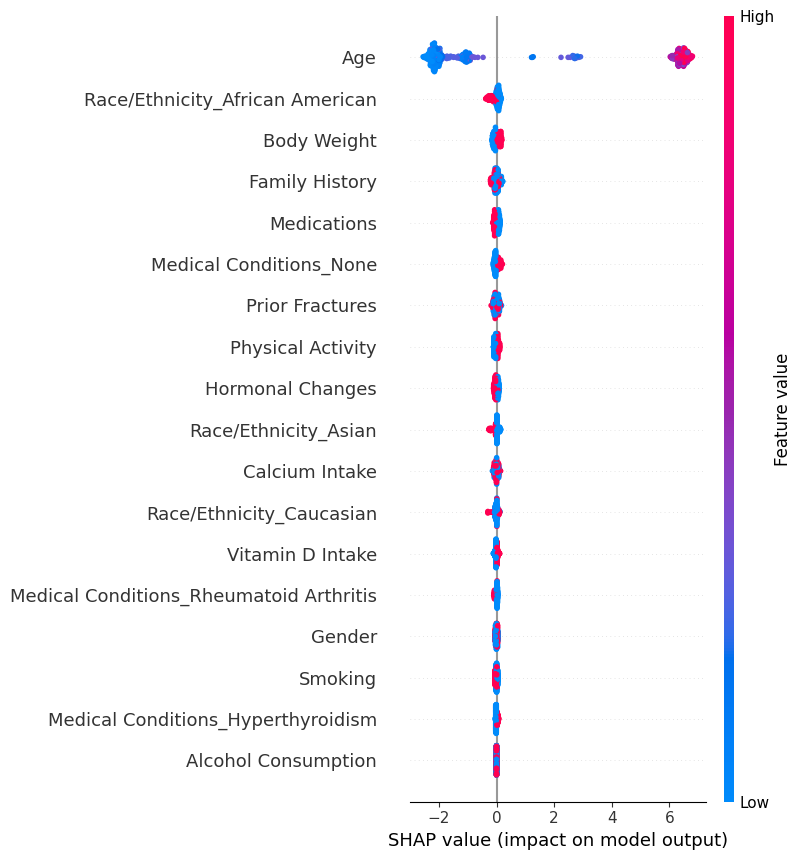

In [ ]:
shap.summary_plot(shap_values, X_test)

B. Random Forest

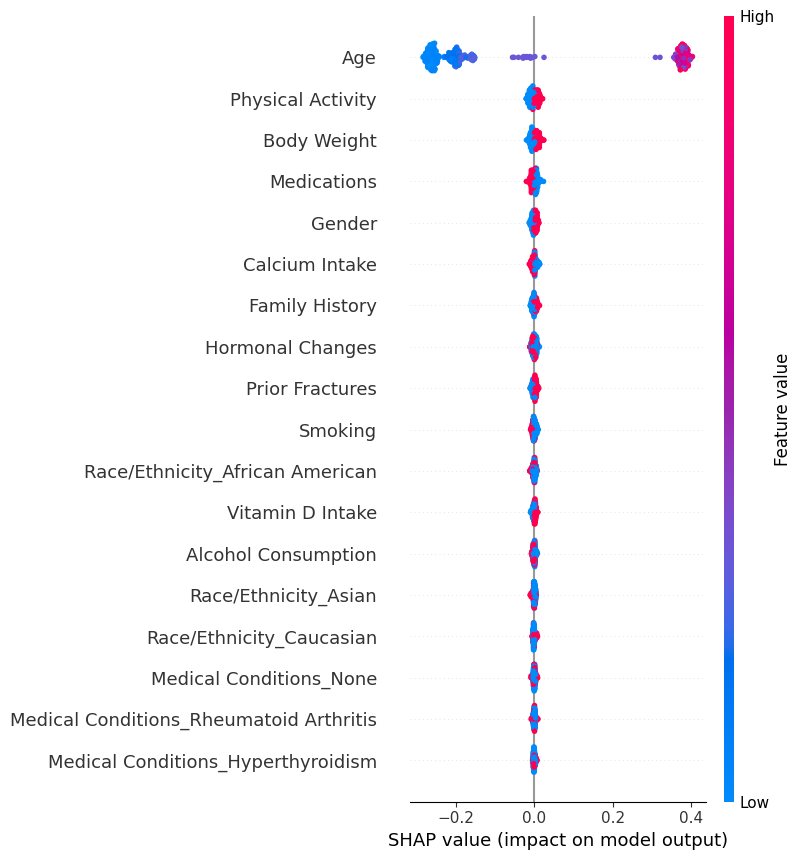

In [ ]:
shap.summary_plot(shap_values_rf_plot, X_test)

A. Perbandingan Random Forest dan XGBoost

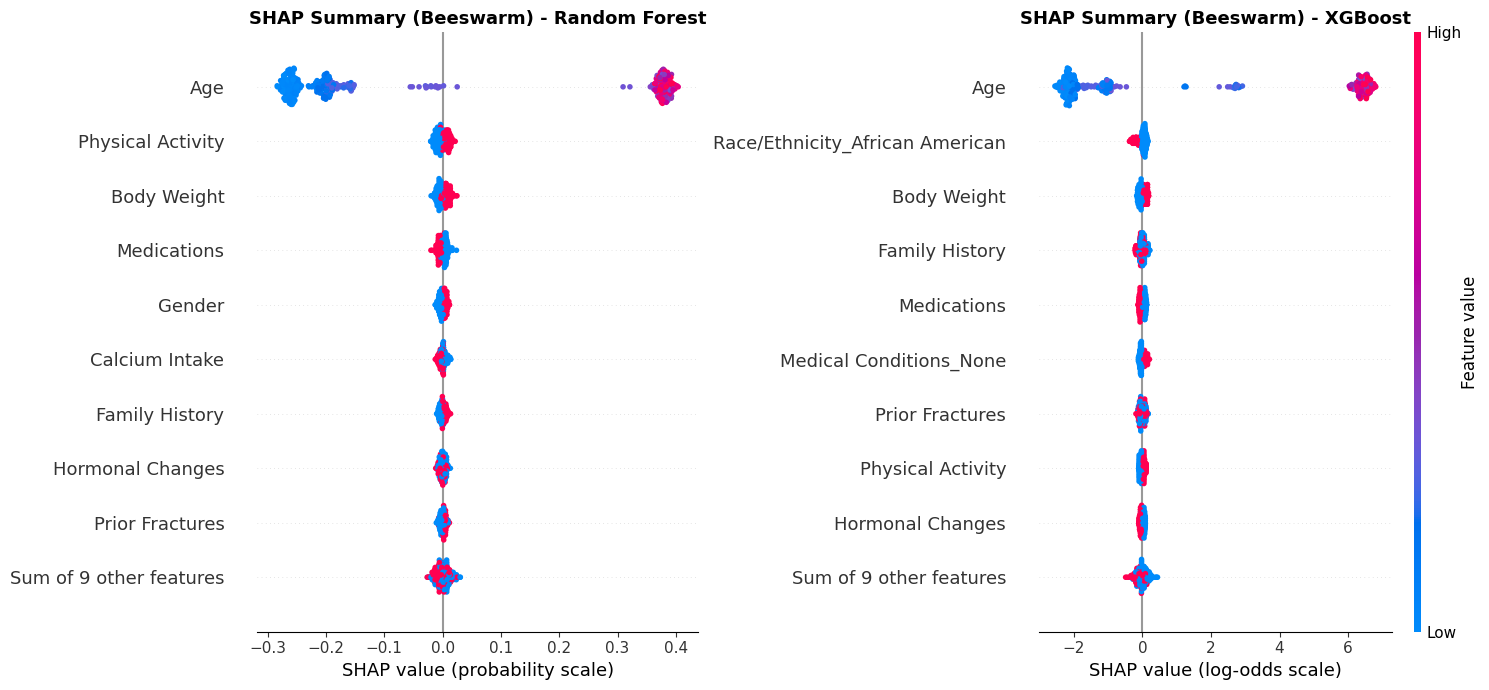

In [ ]:
exp_rf = shap.Explanation(values=shap_values_rf_plot, data=X_test.values, feature_names=X_test.columns.tolist())
exp_xgb = shap.Explanation(values=shap_values, data=X_test.values, feature_names=X_test.columns.tolist())

# Urutan fitur MASING-MASING model (berdasarkan mean |SHAP| model itu sendiri)
order_rf = np.argsort(np.abs(shap_values_rf_plot).mean(axis=0))[::-1]
order_xgb = np.argsort(np.abs(shap_values).mean(axis=0))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

shap.plots.beeswarm(exp_rf, order=order_rf, max_display=10, ax=axes[0], show=False, color_bar=False, plot_size=None)
axes[0].set_title('SHAP Summary (Beeswarm) - Random Forest', fontsize=13, fontweight='bold')
axes[0].set_xlabel('SHAP value (probability scale)')

shap.plots.beeswarm(exp_xgb, order=order_xgb, max_display=10, ax=axes[1], show=False, color_bar=True, plot_size=None)
axes[1].set_title('SHAP Summary (Beeswarm) - XGBoost', fontsize=13, fontweight='bold')
axes[1].set_xlabel('SHAP value (log-odds scale)')

plt.tight_layout()
plt.savefig('figure_5_shap_beeswarm.png', dpi=350, bbox_inches='tight')
plt.show()

In [ ]:
# Rata-rata |SHAP| tiap fitur. CATATAN SKALA: Random Forest dihitung pada skala probabilitas,
# XGBoost pada skala log-odds -> nilai mentah TIDAK sebanding. Yang dibandingkan adalah
# peringkat dan porsi relatif (% dari total mean |SHAP| tiap model).
importance_rf = np.abs(shap_values_rf_plot).mean(axis=0)
importance_xgb = np.abs(shap_values).mean(axis=0)

share_rf = importance_rf / importance_rf.sum() * 100
share_xgb = importance_xgb / importance_xgb.sum() * 100

df_importance_compare = pd.DataFrame({
    'Feature': X_test.columns,
    'RF_Importance': importance_rf,
    'RF_Share_%': share_rf,
    'RF_Rank': pd.Series(importance_rf).rank(ascending=False).astype(int).values,
    'XGB_Importance': importance_xgb,
    'XGB_Share_%': share_xgb,
    'XGB_Rank': pd.Series(importance_xgb).rank(ascending=False).astype(int).values,
}).sort_values('XGB_Importance', ascending=False)

print(df_importance_compare.round(4).to_string(index=False))

                                Feature  RF_Importance  RF_Share_%  RF_Rank  XGB_Importance  XGB_Share_%  XGB_Rank
                                    Age         0.2730     82.9693        1          3.4389    81.719902         1
        Race/Ethnicity_African American         0.0026      0.7792       11          0.0939     2.230800         2
                            Body Weight         0.0070      2.1228        3          0.0783     1.861000         3
                         Family History         0.0035      1.0582        7          0.0666     1.581500         4
                            Medications         0.0049      1.5029        4          0.0655     1.556600         5
                Medical Conditions_None         0.0018      0.5412       16          0.0619     1.470200         6
                        Prior Fractures         0.0033      0.9888        9          0.0599     1.424400         7
                      Physical Activity         0.0076      2.3013        2     

### 13.2 SHAP Feature Importance / Bar Plot

A. XGBoost

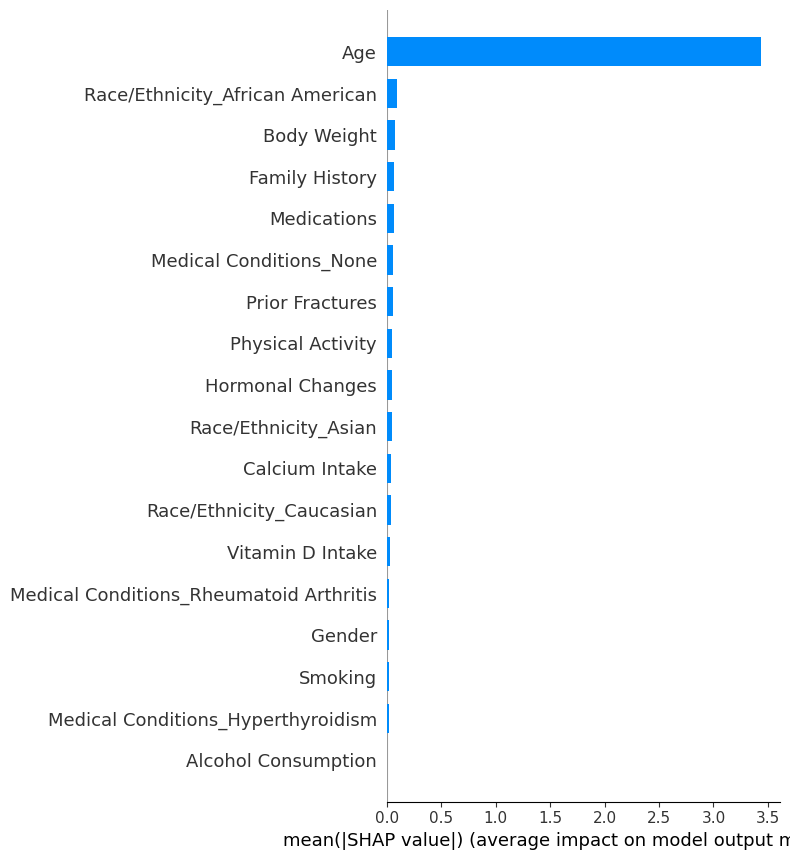

In [ ]:
shap.summary_plot(shap_values, X_test, plot_type='bar')

B. Random Forest

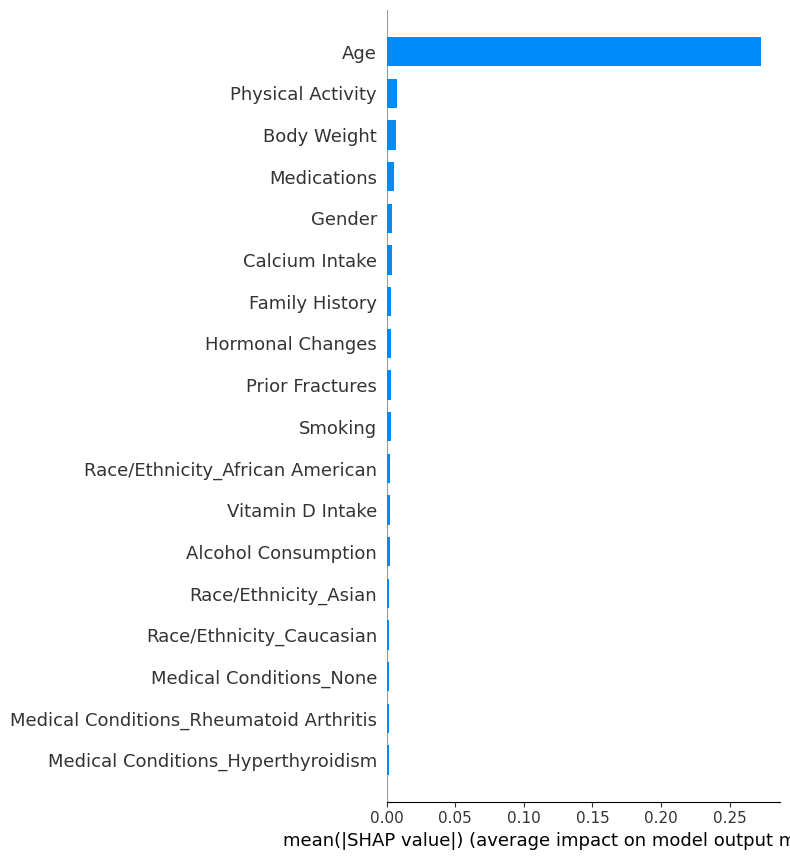

In [ ]:
shap.summary_plot(shap_values_rf_plot, X_test, plot_type='bar')

### 13.3 Perbandingan SHAP: Random Forest vs XGBoost

Menghitung dan membandingkan nilai SHAP dari kedua model untuk melihat apakah keduanya sepakat mengenai fitur mana yang paling berpengaruh.

In [ ]:
# Hitung rata-rata NILAI ABSOLUT SHAP tiap fitur untuk Random Forest
# (dijadikan absolut karena kita hanya peduli SEBERAPA BESAR pengaruhnya, bukan arahnya)
importance_rf = np.abs(shap_values_rf_plot).mean(axis=0)

# Hitung rata-rata nilai absolut SHAP tiap fitur untuk XGBoost (sudah dihitung sebelumnya di shap_values)
importance_xgb = np.abs(shap_values).mean(axis=0)

# Cek ukuran array, harus sama-sama sepanjang jumlah fitur (18)
print("Shape importance_rf:", importance_rf.shape)
print("Shape importance_xgb:", importance_xgb.shape)

# Gabungkan kedua hasil importance ke dalam satu tabel perbandingan
df_importance_compare = pd.DataFrame({
    'Feature': X_test.columns,       # nama tiap fitur
    'RF_Importance': importance_rf,  # tingkat kepentingan fitur menurut Random Forest
    'XGB_Importance': importance_xgb # tingkat kepentingan fitur menurut XGBoost
}).sort_values('XGB_Importance', ascending=False)  # urutkan dari yang paling berpengaruh

print(df_importance_compare)

Shape importance_rf: (18,)
Shape importance_xgb: (18,)
                                    Feature  RF_Importance  XGB_Importance
0                                       Age       0.273029        3.438879
12          Race/Ethnicity_African American       0.002564        0.093875
4                               Body Weight       0.006985        0.078315
3                            Family History       0.003482        0.066551
10                              Medications       0.004946        0.065506
16                  Medical Conditions_None       0.001781        0.061868
11                          Prior Fractures       0.003254        0.059941
7                         Physical Activity       0.007573        0.048818
2                          Hormonal Changes       0.003447        0.047811
13                     Race/Ethnicity_Asian       0.001935        0.047360
5                            Calcium Intake       0.003866        0.042329
14                 Race/Ethnicity_Caucasian  

In [ ]:
# Top-10 fitur MASING-MASING model (berdasarkan porsi relatif mean |SHAP|)
top_n = 10
idx_rf = np.argsort(share_rf)[::-1][:top_n]
idx_xgb = np.argsort(share_xgb)[::-1][:top_n]

feat_rf, val_rf = X_test.columns[idx_rf].tolist(), share_rf[idx_rf]
feat_xgb, val_xgb = X_test.columns[idx_xgb].tolist(), share_xgb[idx_xgb]

print("Top-10 RF :", feat_rf)
print("Top-10 XGB:", feat_xgb)

Top-10 RF : ['Age', 'Physical Activity', 'Body Weight', 'Medications', 'Gender', 'Calcium Intake', 'Family History', 'Hormonal Changes', 'Prior Fractures', 'Smoking']
Top-10 XGB: ['Age', 'Race/Ethnicity_African American', 'Body Weight', 'Family History', 'Medications', 'Medical Conditions_None', 'Prior Fractures', 'Physical Activity', 'Hormonal Changes', 'Race/Ethnicity_Asian']


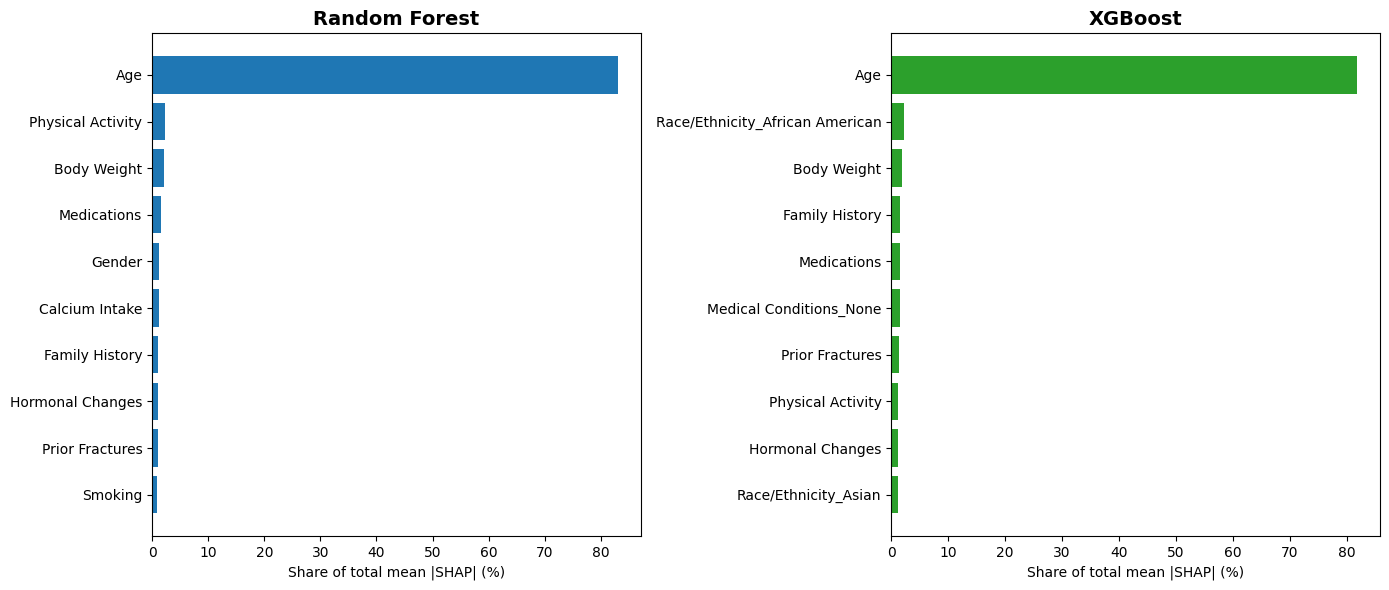

In [ ]:
# Dua bar chart berdampingan; sumbu-y TIDAK dibagi karena tiap model punya top-10 sendiri
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
y_pos = np.arange(top_n)

axes[0].barh(y_pos, val_rf[::-1], color='#1f77b4')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(feat_rf[::-1])
axes[0].set_title('Random Forest', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Share of total mean |SHAP| (%)')

axes[1].barh(y_pos, val_xgb[::-1], color='#2ca02c')
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(feat_xgb[::-1])
axes[1].set_title('XGBoost', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Share of total mean |SHAP| (%)')

plt.tight_layout()
plt.savefig('figure_4_shap_bar.png', dpi=350, bbox_inches='tight')
plt.show()

# **Lampiran: Demo Interpretasi Individual**

### L.1 SHAP Waterfall Plot — Studi Kasus Individu
Menggunakan data pasien dari dataset

**Kasus 1 : Pasien berisiko (aktual = 1) yang diprediksi benar oleh XGBoost, tetapi terlewat oleh Random Forest.**

**Kasus 2 : Pasien berisiko (aktual = 1) yang terlewat oleh kedua model (false negative).**

In [ ]:
# Kasus 1: At-risk (aktual = 1) dan diprediksi BENAR oleh XGBoost tuned (true positive)
idx_tp = np.where((y_pred_xgb_tuned == 1) & (y_test.values == 1))[0]
sample_idx = idx_tp[0]

# Kasus 2: At-risk (aktual = 1) tetapi diprediksi Not-at-risk oleh XGBoost tuned (false negative)
idx_fn = np.where((y_pred_xgb_tuned == 0) & (y_test.values == 1))[0]
sample_idx2 = idx_fn[0]
sample_idx2_rf = sample_idx2   # pasien yang sama dipakai untuk Random Forest

for nama, i in [('Kasus 1 (TP XGBoost)', sample_idx), ('Kasus 2 (FN XGBoost)', sample_idx2)]:
    print(nama, '-> index', i, '| Age:', X_test.iloc[i]['Age'],
          '| Aktual:', y_test.iloc[i],
          '| XGB:', y_pred_xgb_tuned[i], '| RF:', y_pred_rf_tuned[i])

Kasus 1 (TP XGBoost) -> index 1 | Age: 27 | Aktual: 1 | XGB: 1 | RF: 0
Kasus 2 (FN XGBoost) -> index 0 | Age: 22 | Aktual: 1 | XGB: 0 | RF: 0


A. XGBoost (Kasus 1)

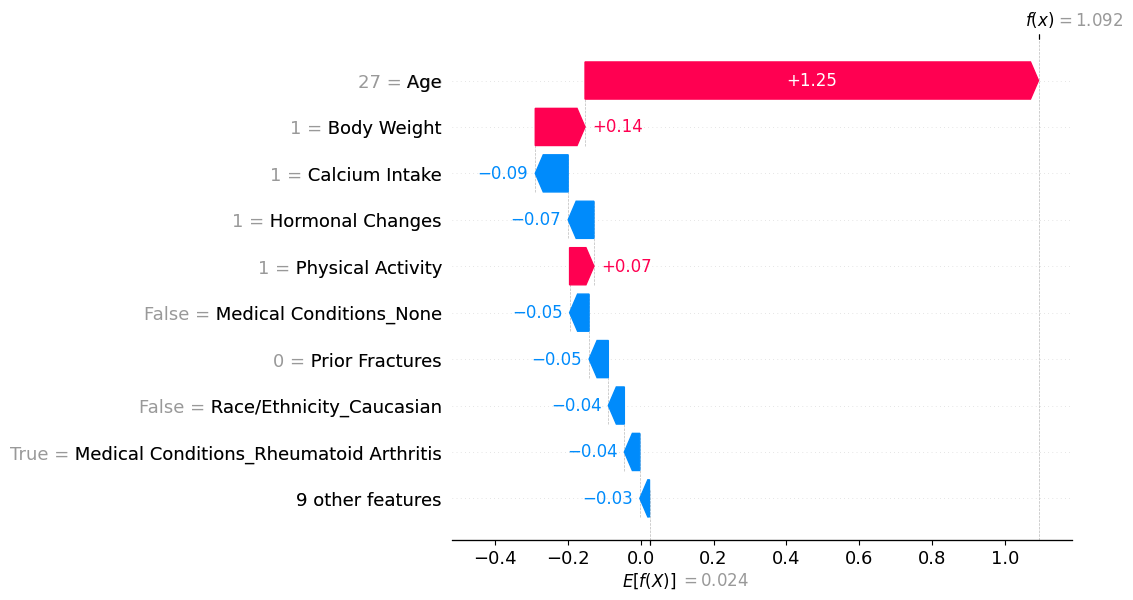

In [ ]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values[sample_idx],
    base_values=explainer.expected_value,
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns.tolist()
))

B. Random Forest (Kasus 1)

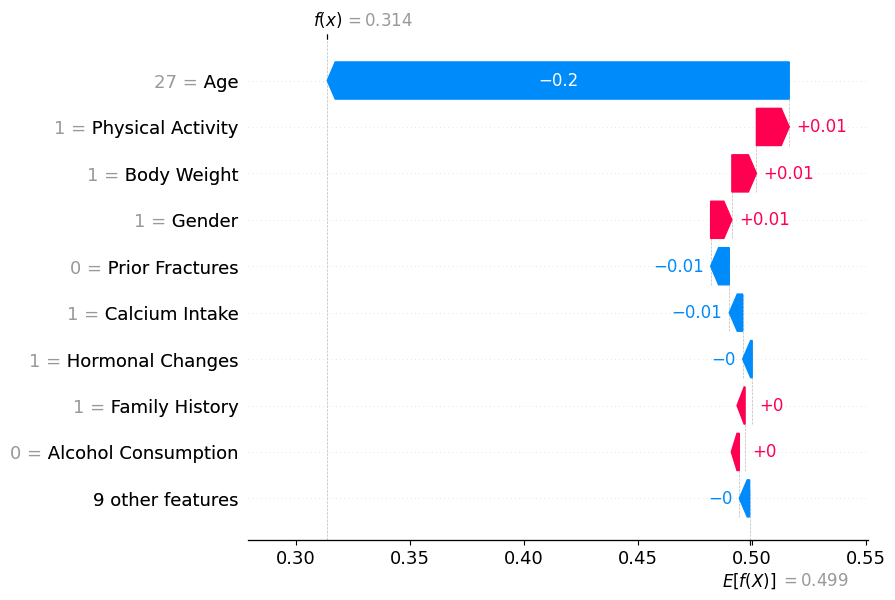

In [ ]:
shap.plots.waterfall(shap.Explanation(
    values=shap_values_rf_plot[sample_idx],
    base_values=explainer_rf.expected_value[1],
    data=X_test.iloc[sample_idx],
    feature_names=X_test.columns.tolist()
))

C. XGBoost (Kasus 2)

Index pasien: 0
Prediksi model: 0 | Aktual: 1


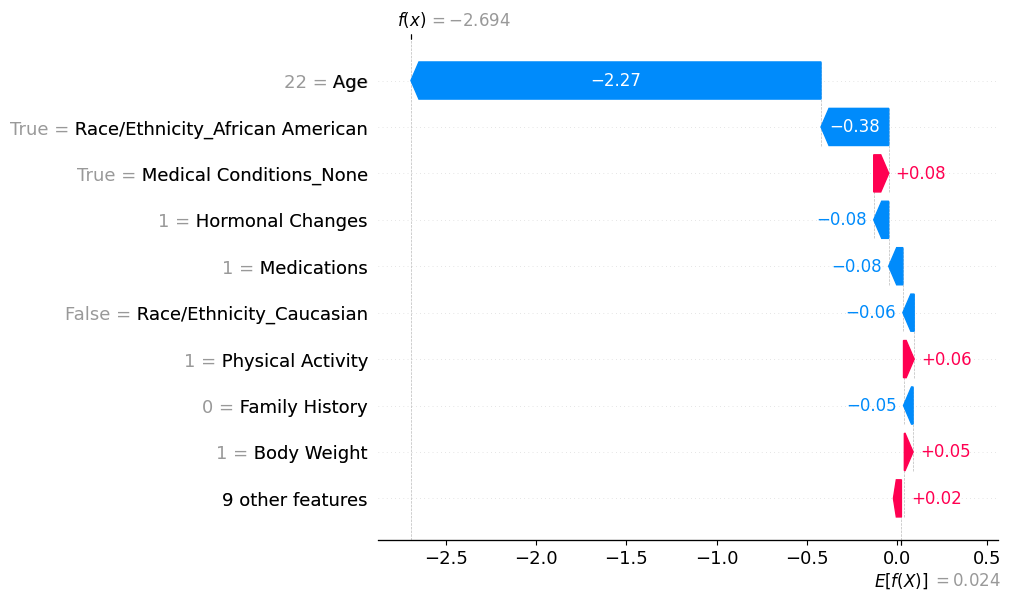

In [ ]:
print("Index pasien:", sample_idx2)
print("Prediksi model:", y_pred_xgb_tuned[sample_idx2], "| Aktual:", y_test.iloc[sample_idx2])

shap.plots.waterfall(shap.Explanation(
    values=shap_values[sample_idx2],
    base_values=explainer.expected_value,
    data=X_test.iloc[sample_idx2],
    feature_names=X_test.columns.tolist()
))

D. Random Forest (Kasus 2)

Index pasien: 0
Prediksi model: 0 | Aktual: 1


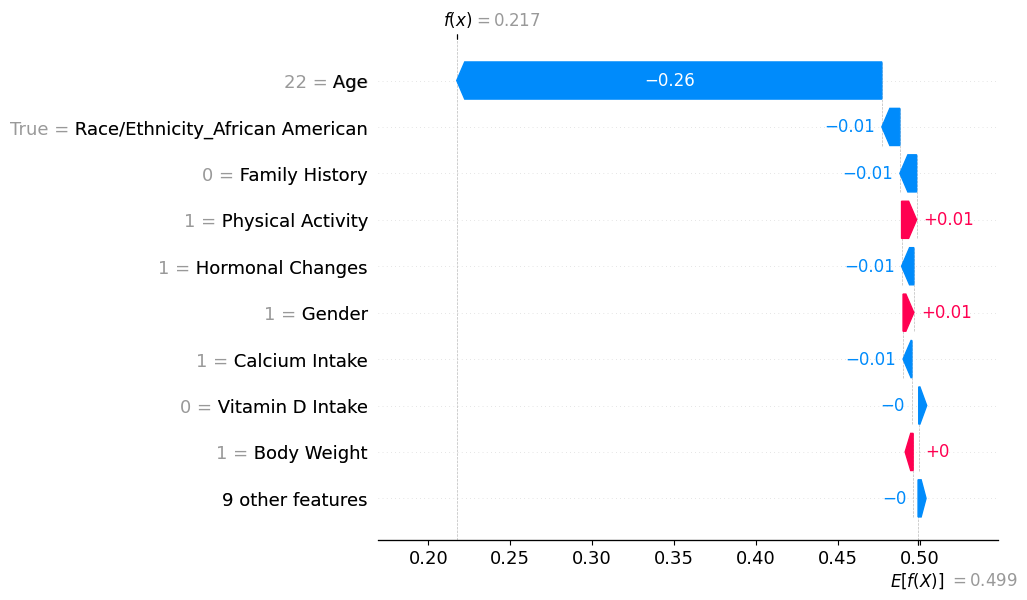

In [ ]:
print("Index pasien:", sample_idx2_rf)
print("Prediksi model:", y_pred_rf_tuned[sample_idx2_rf], "| Aktual:", y_test.iloc[sample_idx2_rf])

shap.plots.waterfall(shap.Explanation(
    values=shap_values_rf_plot[sample_idx2_rf],
    base_values=explainer_rf.expected_value[1],
    data=X_test.iloc[sample_idx2_rf],
    feature_names=X_test.columns.tolist()
))

### L.2 SHAP Dependence Plot — Fitur Age

Menunjukkan hubungan detail antara nilai usia (Age) dan pengaruhnya terhadap prediksi risiko osteoporosis, untuk melihat pada usia berapa risiko mulai meningkat tajam.

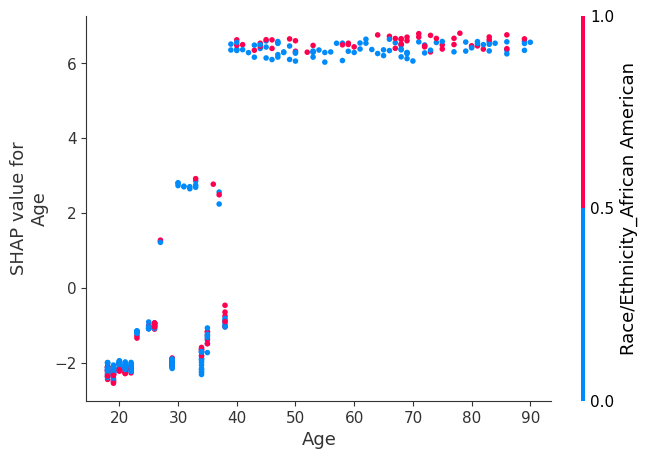

In [ ]:
# shap.dependence_plot menunjukkan hubungan antara NILAI suatu fitur (sumbu X)
# dengan PENGARUHNYA terhadap prediksi model / nilai SHAP (sumbu Y)
# "Age"       -> fitur yang ingin dianalisis
# shap_values -> nilai SHAP yang sudah dihitung sebelumnya (dari model XGBoost)
# X_test      -> data test yang sesuai dengan shap_values tersebut
shap.dependence_plot("Age", shap_values, X_test)

### L.3 Studi Kasus: Simulasi Pasien Baru (Belum Diketahui Status Osteoporosisnya)

In [ ]:
# Buat data pasien baru secara manual (dibuat sendiri, bukan dari dataset)
# Angka/kategori di bawah ini merepresentasikan kondisi pasien hipotetis:
# - Usia 65 tahun, Wanita, sudah pascamenopause, ada riwayat keluarga osteoporosis, dst
pasien_baru = pd.DataFrame([{
    'Age': 65,
    'Gender': 0,                  # 0 = Female (lihat tabel keterangan encoding)
    'Hormonal Changes': 1,        # 1 = Postmenopausal
    'Family History': 1,          # 1 = Yes
    'Body Weight': 1,             # 1 = Underweight
    'Calcium Intake': 1,          # 1 = Low
    'Vitamin D Intake': 0,        # 0 = Insufficient
    'Physical Activity': 1,       # 1 = Sedentary
    'Smoking': 0,                 # 0 = No
    'Alcohol Consumption': 0,     # 0 = Moderate
    'Medications': 1,             # 1 = None
    'Prior Fractures': 0,         # 0 = No
    # Kolom hasil One-Hot Encoding untuk Race/Ethnicity dan Medical Conditions,
    # perlu diisi False semua kecuali kategori yang sesuai kondisi pasien
}])

# Pastikan urutan & jumlah kolom SAMA PERSIS dengan X_train,
# kolom yang belum diisi di atas (hasil one-hot) otomatis diisi 0/False
pasien_baru = pasien_baru.reindex(columns=X_train.columns, fill_value=False)

print("Data pasien baru:")
print(pasien_baru)

Data pasien baru:
   Age  Gender  Hormonal Changes  Family History  Body Weight  Calcium Intake  \
0   65       0                 1               1            1               1   

   Vitamin D Intake  Physical Activity  Smoking  Alcohol Consumption  \
0                 0                  1        0                    0   

   Medications  Prior Fractures  Race/Ethnicity_African American  \
0            1                0                            False   

   Race/Ethnicity_Asian  Race/Ethnicity_Caucasian  \
0                 False                     False   

   Medical Conditions_Hyperthyroidism  Medical Conditions_None  \
0                               False                    False   

   Medical Conditions_Rheumatoid Arthritis  
0                                    False  


A. XGBoost

In [ ]:
# Prediksi status osteoporosis pasien baru ini menggunakan model XGBoost yang sudah dilatih
prediksi = xgb_model_tuned.predict(pasien_baru)[0]
probabilitas = xgb_model_tuned.predict_proba(pasien_baru)[0]

label = "BERISIKO" if prediksi == 1 else "TIDAK BERISIKO"
print(f"Hasil prediksi: {label}")
print(f"Probabilitas -> Tidak Berisiko: {probabilitas[0]:.2%}, Berisiko: {probabilitas[1]:.2%}")

Hasil prediksi: BERISIKO
Probabilitas -> Tidak Berisiko: 0.12%, Berisiko: 99.88%


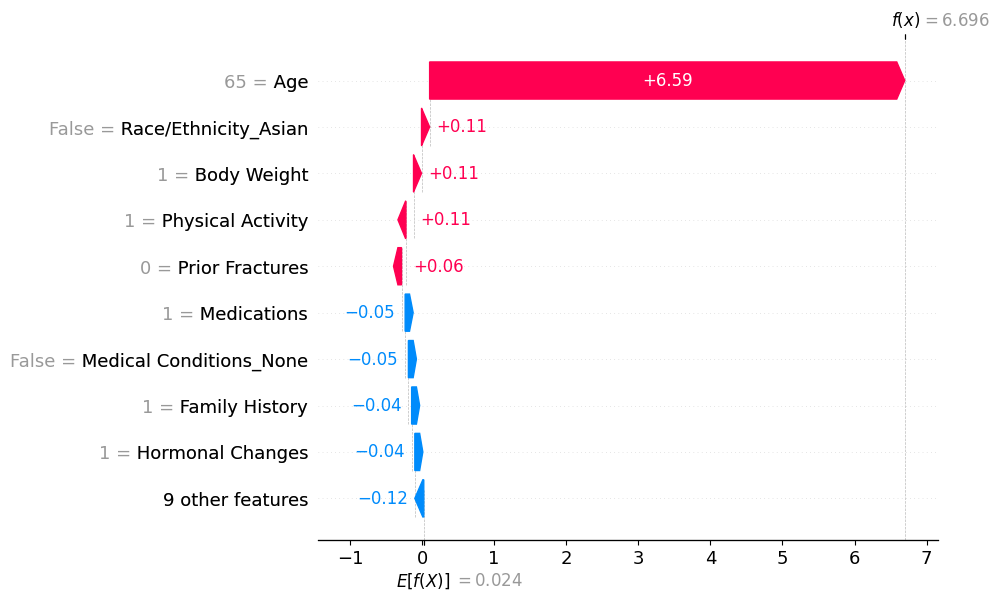

In [ ]:
# Menjelaskan KENAPA model memprediksi demikian, menggunakan SHAP waterfall plot
shap_values_pasien_baru = explainer.shap_values(pasien_baru)

shap.plots.waterfall(shap.Explanation(
    values=shap_values_pasien_baru[0],
    base_values=explainer.expected_value,
    data=pasien_baru.iloc[0],
    feature_names=pasien_baru.columns.tolist()
))

B. Random Forest

In [ ]:
# Prediksi status osteoporosis pasien baru ini menggunakan model Random Forest yang sudah dilatih
prediksi_rf = rf_model_tuned.predict(pasien_baru)[0]
probabilitas_rf = rf_model_tuned.predict_proba(pasien_baru)[0]

label_rf = "BERISIKO" if prediksi_rf == 1 else "TIDAK BERISIKO"
print(f"Hasil prediksi: {label_rf}")
print(f"Probabilitas -> Tidak Berisiko: {probabilitas_rf[0]:.2%}, Berisiko: {probabilitas_rf[1]:.2%}")

Hasil prediksi: BERISIKO
Probabilitas -> Tidak Berisiko: 12.37%, Berisiko: 87.63%


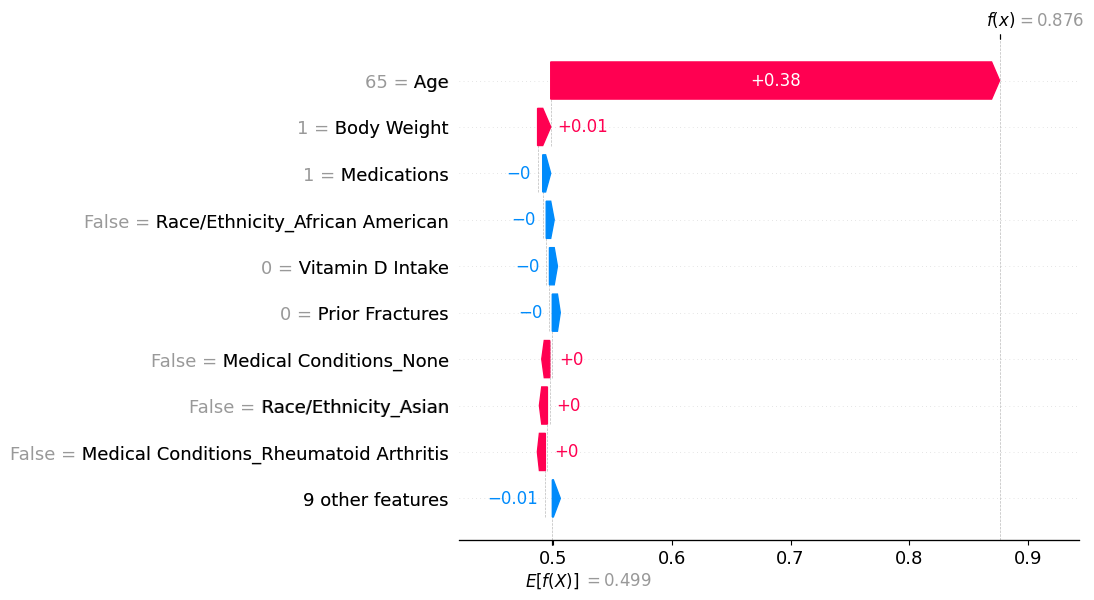

In [ ]:
# Menjelaskan KENAPA model memprediksi demikian, menggunakan SHAP waterfall plot (Random Forest)
shap_values_pasien_baru_rf = explainer_rf.shap_values(pasien_baru)

# Ubah ke numpy array dan ambil irisan kelas 1 (Berisiko), sama seperti proses shap_values_rf_plot
shap_values_pasien_baru_rf_arr = np.array(shap_values_pasien_baru_rf)[:, :, 1]

shap.plots.waterfall(shap.Explanation(
    values=shap_values_pasien_baru_rf_arr[0],
    base_values=explainer_rf.expected_value[1],
    data=pasien_baru.iloc[0],
    feature_names=pasien_baru.columns.tolist()
))

# **Analisis dan Kesimpulan**

In [ ]:
import sklearn, xgboost, shap, pandas, numpy, matplotlib
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("shap:", shap.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("matplotlib:", matplotlib.__version__)

scikit-learn: 1.6.1
xgboost: 3.4.1
shap: 0.54.1
pandas: 2.2.3
numpy: 2.4.6
matplotlib: 3.10.0


### 1. Ringkasan Performa Model

| Skema evaluasi | Random Forest | XGBoost |
|---|---|---|
| Baseline, data uji split 42 | 82,65% | 85,97% |
| Tuned, data uji split 42 | 83,67% | 88,27% |
| Tuning ulang per split, rata-rata 5 random state | 85,82% ± 1,77% | 91,33% ± 1,92% |
| Hanya usia (tanpa tuning), rata-rata 5 random state | 88,47% ± 1,32% | 91,48% ± 1,86% |

Catatan: skor CV pada data training (baseline 85,57% / 89,08%; tuned 86,27% / 91,57%) tidak dimasukkan ke tabel karena skor tuned adalah nilai terbaik hasil pencarian grid, sehingga tidak sebanding dengan skor baseline.

Pada model 18 fitur, XGBoost lebih akurat daripada Random Forest di setiap skema yang sebanding dan di kelima random state. Variasi antar-random state kedua model setara (SD 1,92% vs 1,77%), sehingga XGBoost tidak dapat disebut lebih stabil. Selisih antara tuning ulang per split dan parameter tetap dari split 42 sangat kecil (sekitar 0,1 poin).

Model yang hanya memakai usia mencapai akurasi yang setara dengan XGBoost 18 fitur (91,48% vs 91,33%) dan lebih tinggi daripada Random Forest 18 fitur. Pada dataset ini, 17 fitur lain tidak terbukti menambah kemampuan prediksi di atas usia.

Recall kelas At-risk pada data uji adalah 0,6888 (Random Forest tuned) dan 0,7704 (XGBoost tuned); turun sedikit dibanding baseline (0,7041 dan 0,7857). Menurunkan threshold berdasarkan training-CV (target recall 0,90) hanya menaikkan recall data uji menjadi 0,8571 (RF) dan 0,8265 (XGBoost), dengan false positive naik menjadi 72 dan 51. Target tidak tercapai pada data uji.


---

### 2. Catatan Mengenai Distribusi Kelas dan Struktur Label

Distribusi kelas target (Osteoporosis) tercatat seimbang sempurna (979 berbanding 979). Hal ini kemungkinan besar merupakan hasil kurasi oleh penyedia dataset di Kaggle, bukan proses yang dilakukan dalam penelitian ini, sehingga akurasi yang dilaporkan belum tentu berlaku pada populasi nyata yang kelas At-risk-nya minoritas.

Deskripsi dataset tidak menyebutkan bagaimana label ditetapkan (diagnosis DXA, penilaian klinis, laporan responden, atau aturan tertentu), serta bagaimana, di mana, dan kapan data dikumpulkan. Eksplorasi data menunjukkan struktur yang kuat antara usia dan label:

- Seluruh 979 record Not-at-risk berusia 18 sampai 38 tahun.
- Seluruh 702 record berusia 39 tahun ke atas berlabel At-risk (100%).
- Kedua kelas hanya bercampur pada usia ≤ 38 tahun (1256 record, 277 di antaranya At-risk).
- Satu aturan ambang usia (Age ≤ 38,5 → Not-at-risk) mencapai akurasi 83,93% pada data uji dengan presisi 1,0 dan recall 0,6786.

Dengan struktur tersebut, hasil penelitian ini diposisikan sebagai klasifikasi label dataset, bukan sebagai prediksi diagnosis klinis atau risiko di masa depan. Kemampuan model yang setara dengan model hanya-usia, serta dominasi usia pada analisis SHAP, perlu dibaca dalam konteks struktur label ini.


---
### 3. Interpretasi SHAP

Analisis SHAP dihitung pada model hasil tuning (`rf_model_tuned` dan `xgb_model_tuned`) menggunakan data uji split 42. Nilai SHAP Random Forest berada pada skala probabilitas, sedangkan XGBoost pada skala log-odds, sehingga nilai mentah kedua model tidak dibandingkan langsung. Yang dibandingkan adalah peringkat fitur dan porsi relatif terhadap total mean |SHAP| tiap model.

- **Usia sangat dominan di kedua model.** Porsinya 82,97% (Random Forest) dan 81,72% (XGBoost). Mean |SHAP| usia sekitar 36 kali fitur peringkat kedua pada Random Forest (0,2730 vs 0,0076, Physical Activity) dan sekitar 37 kali pada XGBoost (3,4389 vs 0,0939, Race/Ethnicity_African American).
- **Fitur lain berkontribusi sangat kecil.** Tidak ada fitur selain usia yang melebihi sekitar 2,3% (Physical Activity 2,30% pada Random Forest, Race/Ethnicity_African American 2,23% pada XGBoost). Ketujuh belas fitur lain secara bersama-sama hanya menyumbang sekitar 17% (Random Forest) dan 18% (XGBoost).
- **Tujuh dari sepuluh fitur teratas sama di kedua model:** Age, Body Weight, Medications, Physical Activity, Family History, Hormonal Changes, dan Prior Fractures. Body Weight berada di peringkat 3 pada keduanya. Physical Activity berada di peringkat 2 pada Random Forest tetapi peringkat 8 pada XGBoost.
- **Perbedaan peringkat hanya pada fitur berporsi kecil.** Alcohol Consumption bernilai 0 pada XGBoost (peringkat 18) dan 0,63% pada Random Forest (peringkat 13). Race/Ethnicity_African American (peringkat 2), Medical Conditions_None (peringkat 6), dan Race/Ethnicity_Asian (peringkat 10) masuk sepuluh besar XGBoost, sedangkan pada Random Forest berada di peringkat 11, 16, dan 14. Selisih porsi antarfitur sangat tipis, sehingga peringkat sekunder ini rapuh dan tidak ditafsirkan secara klinis.

Dominasi usia konsisten dengan struktur label dataset (lihat bagian 2) dan dengan hasil model hanya-usia, sehingga tidak dibaca sebagai temuan klinis yang independen. Pada plot beeswarm, nilai usia yang tinggi (merah) sebagian besar berada di sisi SHAP positif, yaitu mendorong prediksi ke kelas At-risk.


---

### 4. Kesimpulan Sementara

1. Pada model 18 fitur, XGBoost lebih akurat daripada Random Forest di setiap skema yang sebanding: data uji split 42 (88,27% vs 83,67% setelah tuning) dan rata-rata lima random state dengan tuning ulang per split (91,33% vs 85,82%). Variasi antar-random state kedua model setara (SD 1,92% vs 1,77%), sehingga keunggulan XGBoost tidak dapat dikaitkan dengan stabilitas yang lebih baik.
2. Tuning hyperparameter menaikkan akurasi data uji sebesar 2,3 poin pada XGBoost dan 1,0 poin pada Random Forest, tetapi menurunkan recall At-risk sedikit pada keduanya (XGBoost 0,7857 → 0,7704; Random Forest 0,7041 → 0,6888). Skor CV baseline dan tuned tidak dibandingkan sebagai bukti peningkatan karena skemanya tidak sebanding.
3. Model yang hanya memakai usia mencapai akurasi setara dengan XGBoost 18 fitur (91,48% vs 91,33%) dan lebih tinggi daripada Random Forest 18 fitur (88,47% vs 85,82%). Pada dataset ini, 17 fitur lain tidak terbukti menambah kemampuan prediksi di atas usia.
4. Seluruh individu berusia ≥ 39 tahun berlabel At-risk, dan seluruh 45 kasus At-risk yang terlewat XGBoost tuned berasal dari subgrup usia ≤ 38. Di subgrup itu, model hanya-usia dan model 18 fitur sama-sama hanya mendeteksi 18 dari 63 kasus At-risk (recall 0,29).
5. Menurunkan threshold berdasarkan training-CV (target recall 0,90) tidak mencapai target pada data uji (recall 0,83 untuk XGBoost dan 0,86 untuk Random Forest) dan menaikkan false positive dari 1 menjadi 51 (XGBoost) dan dari 3 menjadi 72 (Random Forest). Manfaat klinis sebagai alat pre-screening belum terbukti.
6. SHAP pada model tuned menunjukkan usia menyumbang lebih dari 80% total mean |SHAP| di kedua model. Peringkat fitur sekunder berporsi kecil dan berbeda antar-model, sehingga dibaca sebagai temuan eksploratif.


---

### 5. Keterbatasan dan Saran Penelitian Lanjutan

**Keterbatasan**

- **Asal label tidak diketahui.** Deskripsi dataset tidak menjelaskan bagaimana label ditetapkan. Seluruh individu berusia ≥ 39 tahun berlabel At-risk dan seluruh Not-at-risk berusia ≤ 38 tahun, sehingga hasil dibatasi pada klasifikasi label dataset, bukan diagnosis atau prediksi risiko klinis.
- **Distribusi kelas seimbang secara buatan** (979 vs 979). Akurasi belum tentu berlaku pada populasi nyata yang kelas At-risk-nya minoritas.
- **Satu dataset publik tanpa validasi eksternal.** Fitur yang tersedia tidak mencakup kepadatan tulang (BMD) atau biomarker klinis lain.
- **Lima random state tidak saling independen.** Pembagian data saling tumpang tindih dan tidak ada uji signifikansi, sehingga selisih kecil (misalnya 91,48% vs 91,33% antara model hanya-usia dan XGBoost 18 fitur) dibaca sebagai "tidak dapat dibedakan".
- **Model hanya-usia memakai konfigurasi sederhana tanpa tuning**, dan analisis subgrup usia ≤ 38 memakai hyperparameter hasil tuning pada seluruh data (bukan pada subgrup). Jumlah kasus At-risk pada subgrup uji kecil (63) dan hanya dari satu split.
- **Pemilihan threshold** dilakukan dari prediksi out-of-fold pada data training dengan satu skema fold, dan target recall tidak tercapai pada data uji.
- **Skala SHAP berbeda antar-model** (probabilitas untuk Random Forest, log-odds untuk XGBoost), sehingga hanya peringkat dan porsi relatif yang dibandingkan. Peringkat fitur sekunder berporsi kecil dan tidak ditafsirkan secara klinis, termasuk kemunculan fitur Race/Ethnicity dan Medical Conditions_None di sepuluh besar XGBoost.

**Saran penelitian lanjutan**

- Memvalidasi model pada kohort klinis nyata dengan label yang diketahui asalnya (misalnya diagnosis DXA) dan distribusi kelas alami.
- Menguji apakah fitur gaya hidup menambah prediksi pada subgrup usia muda (≤ 38), dengan tuning khusus pada subgrup tersebut.
- Menyamakan ruang keluaran SHAP kedua model (misalnya keduanya dalam probabilitas) agar besar kontribusi dapat dibandingkan langsung.
- Menambahkan algoritma, ukuran efek dengan interval kepercayaan, dan evaluasi prospektif terhadap diagnosis berbasis DXA.
